In [1]:
META = {
    "id": "H0002",
    "title": "Vol-scaled time-series momentum, 5 coins",
    "status": "confirmed",  # open | confirmed | rejected
    "result": "WEAK-confirmed (re-run 2026-10-30 on pre-holdout data, block-bootstrap CI): L=28 h=7 up-minus-down diff > 0 on 5/5 coins but BH p_adj < 0.05 on no coin after the 2026-11-02 lag fix (lags 3h; SOL 0.059, was 0.022; other coins not rechecked); 5-coin long/flat net p_adj 0.026, Sharpe 1.27 vs B&H 0.97, 2022+ Sharpe 0.92 vs 0.90 (n.s.). Built into strategies/S0004.",
    "timeframes": ["1d"],
    "data_end": "2025-09-30",
}

# H0002 - Vol-scaled time-series momentum, 5 coins

**Question in plain words:** if a coin has gone up over the last few weeks, does it keep going up over the next week -
and can a simple "hold it only while it is trending up" rule beat holding it all the time?

Summary card below; the full story (sources, maths, tests, verdict) follows. Statistical methods are listed in the
Methods section.

In [2]:
from qr.report import callout
callout("amber", "Verdict: WEAK-confirmed - real but modest, and fading after 2022",
    "<ul style='margin:4px 0'>"
    "<li><b>Per coin:</b> after a positive 28-day return, the next 7 days beat the after-negative case by "
    "+1.2% to +5.4% on <b>all 5 coins</b>, but only SOL survives the multiple-testing correction "
    "(BH p<sub>adj</sub> 0.022; BTC 0.12, ETH 0.08).</li>"
    "<li><b>Portfolio:</b> long/flat vol-scaled trend on 5 coins, net of costs: Sharpe <b>1.27</b> vs 0.97 for "
    "vol-scaled buy &amp; hold (HAC p<sub>adj</sub> 0.026). The gain is <b>lower risk</b>, not higher return.</li>"
    "<li><b>Since 2022:</b> Sharpe 0.92 vs 0.90 - the edge over buy &amp; hold mostly disappears.</li>"
    "<li><b>For trading:</b> this is the base of the S0004 trend-ensemble strategy in this repo.</li></ul>")

## Glossary

| Name | Maths | Plain meaning | Units |
|---|---|---|---|
| $P_t$, `close` | | Close of the daily bar that opens at $t$ (UTC) | USDT |
| $r_t$ | $P_t/P_{t-1}-1$ | One-day return | fraction |
| $L$, `L=7/28/84` | | Look-back window | days |
| $R_{L,t}$, `R` | $P_t/P_{t-L}-1$ | Past $L$-day return (the trend) | fraction |
| $\sigma_t$, `sigma` | std of last 60 daily log returns | Recent daily volatility | per day |
| $z_{L,t}$, `z` | $R_{L,t}/(\sigma_t\sqrt{L})$ | Trend strength in volatility units | unitless |
| $E_{L,t}$ | $\mathbb 1[R_{L,t}>0]$ | "Up-trend" event | 0/1 |
| $h$, `horizon` | | Forward horizon | days |
| $r^{(h)}_t$ | $P_{t+h}/P_t-1$ | Forward return (the target; never an input) | fraction |
| `diff`, `effect` | $\bar r^{(h)}\mid E - \bar r^{(h)}\mid \neg E$ | Mean forward return after up-trend minus after down/flat trend | fraction per $h$ days |
| `n_event`, `n_base` | | Number of up-trend / other days | days |
| `hac_t`, `hac_p` | | Newey-West t-statistic and two-sided p-value | |
| `hac_p_adj` | | Benjamini-Hochberg (BH) adjusted p across all 231 tests here | |
| `boot_lo`, `boot_hi`, `ci_lo`, `ci_hi` | | 95% moving-block bootstrap CI of `diff` | fraction |
| `MDE` | $2.8\,\mathrm{se}_{\mathrm{HAC}}$ | Minimum detectable effect (80% power, 5% two-sided) | fraction |
| $w_t$ | $\min(0.02/\sigma_t, 2)$ | Vol-scaled position size (2% daily vol target) | x capital |
| `LS` | $\operatorname{sign}(R_{L,t})\,w_t$ | Long/short trend portfolio | |
| `LF` | $\mathbb 1[R_{L,t}>0]\,w_t$ | Long/flat trend portfolio | |
| `BH` (column) | $w_t$ | **Buy & hold**, vol-scaled (benchmark). In prose: B&H, to avoid confusion with the BH correction | |
| `_net` | | After costs: $0.115\%$ per unit of position change | |
| `LF-BH` | | Daily return of LF minus B&H | |
| `ann_ret`, `sharpe` | $365\,\bar r$, $\bar r/s\sqrt{365}$ | Annualised mean return, Sharpe ratio | |
| `flips_per_yr` | | Sign changes of $R_L$ per coin per year | |
| `gross_minus_flips` | `ann_ret` $-$ flips $\times 0.23\%$ | Rough net return of LS | per year |
| `Q1..Q5`, `Q5-Q1` | | Quintiles of $z_L$ (Q5 = strongest up-trend); top minus bottom | fraction per 7d |
| `spearman`, `spearman_p` | | Rank correlation $z_L$ vs 7-day forward return; its p-value (ignores overlap - descriptive) | |
| `source` `okx` / `cb` | | OKX spot USDT / Coinbase USD | |
| `PORT`, `PORT_CB` | | 5-coin OKX portfolio / 3-coin Coinbase portfolio | |
| `period` | | `full` 2018-2025-09, `2018-2021`, `2022+`, `2015-2017` (Coinbase only) | |

## Literature review

**1. Moskowitz, Ooi & Pedersen (2012), "Time series momentum", *Journal of Financial Economics* 104(2), 228-250.**
[PDF](https://w4.stern.nyu.edu/facdir/lpederse/papers/TimeSeriesMomentum.pdf) (fetched and checked 2026-10-30).
- *Tested:* 58 liquid futures - 24 commodities, 12 currency pairs, 9 equity indexes, 13 government bonds -
  January 1965 to December 2009 (main regressions 1985-2009), monthly. Signal: sign of the past $k$-month excess
  return, held $h$ months, position size inversely proportional to ex-ante volatility.
- *Result:* returns persist for 1 to 12 months and partially reverse at longer horizons. The 12-month strategy is
  profitable for **every one of the 58** contracts. The diversified portfolio has an annual Sharpe ratio **above 1**
  (about 2.5x the equity market's), little exposure to standard factors, and an alpha over cross-sectional momentum of
  **76 bp/month, t = 5.90** (Table 5). It does best in extreme markets (the "smile", Fig. 4). Speculators profit at
  the expense of hedgers.
- *Reliability:* top peer-reviewed journal, 45 years, 4 asset classes; widely replicated - the basis of the
  managed-futures (CTA) industry. Data-mining risk low for the 12-month rule, higher for the many $(k,h)$ grids.
  Known critique: Huang, Li, Wang & Zhou (2020, JFE, "Time-series momentum: is it there?") argue that per-asset
  predictability is weak and the pooled evidence is driven by a few assets / by vol scaling (from memory - the
  journal page refused automated access, not verified). Kim, Tse & Wald (2016) attribute much of the profit to vol
  scaling itself.
- *How found:* canonical anomaly, in the Research Lead's round-1 shortlist (SSRN / journal recall).

**2. Liu & Tsyvinski (2021), "Risks and returns of cryptocurrency", *Review of Financial Studies* 34(6), 2689-2727.**
[NBER w24877](https://www.nber.org/papers/w24877) (abstract checked 2026-10-30).
- *Tested:* Bitcoin, Ripple (XRP), Ethereum; returns vs equity, currency, commodity factors; momentum and
  investor-attention proxies.
- *Result (abstract):* "a strong time-series momentum effect", and attention proxies forecast returns. Crypto returns
  have little exposure to traditional asset factors.
- *Reliability:* top journal, but a short sample (mostly 2011-2018, dominated by early bull markets); few coins.
- *Transfer to crypto:* direct - it *is* crypto.

**Why it should (or should not) transfer:** crypto is 24/7, retail- and leverage-heavy, and has no cash flows
to anchor value, so attention-driven trend chasing and slow diffusion of news are plausible - the same
under-reaction / delayed over-reaction story as MOP. Against: crypto trends are short and violent, our daily horizon
is far shorter than MOP's 12 months, and our 5 coins are one correlated bet on BTC.

**Who is on the other side (R3):** late sellers in down-trends (forced deleveraging, capitulation) and
mean-reversion traders fading up-trends; in MOP the losers are hedgers paying for insurance.

**Prior:** about 60% that a weak positive effect exists at 1-12 week horizons, mainly from the cleanest MOP result and
crypto-specific evidence; low confidence that it beats buy & hold on return (crypto drifted up strongly).

## Hypotheses

Three test families, each at $\alpha = 0.05$, Benjamini-Hochberg correction across **all 231 tests** in this notebook
(and again across the round by the Research Lead).

**Family 1 - event study per coin** (coin $i$, look-back $L$, horizon $h$, period):
$$H_0:\ \mathbb E\big[r^{(h)}_t \mid R_{L,t}>0\big] = \mathbb E\big[r^{(h)}_t \mid R_{L,t}\le 0\big]
\qquad H_1:\ \mathbb E\big[r^{(h)}_t \mid R_{L,t}>0\big] \ne \mathbb E\big[r^{(h)}_t \mid R_{L,t}\le 0\big]$$
Two-sided; statistic: HAC t of the event dummy in $r^{(h)}_t = a + b\,E_{L,t} + \varepsilon_t$ with $h$ lags.
The momentum claim is $b>0$.

**Family 2 - monotonicity:** $H_0:\ \rho_S(z_{L,t}, r^{(7)}_t) = 0$ vs $H_1:\ \rho_S \ne 0$ (Spearman; descriptive,
its p ignores overlapping windows).

**Family 3 - portfolio:** daily portfolio return $r^p_t$ of each version (LS, LF, net, B&H, LF-B&H):
$$H_0:\ \mathbb E[r^p_t] = 0 \qquad H_1:\ \mathbb E[r^p_t] \ne 0$$
Two-sided HAC mean test. The key one is LF-B&H: does going flat in down-trends add **return**, or only cut risk?

## Methods

Forward return, event study, HAC t-test,
moving-block bootstrap CI, Benjamini-Hochberg, quintile table + Spearman, Sharpe ratio and its standard error, MDE.
Notebook-specific choices:
- **HAC lags = $h$** because consecutive $h$-day forward returns share $h-1$ days.
- **Bootstrap block = $h$** (since 2026-10-30; the first run used an iid bootstrap whose CIs were too narrow).
- **Costs:** 0.115% per unit of position traded (OKX taker 0.10% + spread/slippage) - a full long-to-short flip
  costs 0.23%.

## Data
OKX spot USDT daily bars for BTC, ETH, XRP, LTC, SOL from 2018-01-11 (SOL from 2020-10-01) to **2025-09-30**
(the final holdout from 2025-10-01 is locked - this re-run no longer sees it; the first run in 2026-10-07 did).
Coinbase USD daily for BTC, ETH, LTC 2015-2017 as an independent earlier sample. Timeframe: **1d only** - the
effect in the papers is monthly, so intraday bars were not tested here; a multi-timeframe re-run is a next
step. Known issues: XRP/LTC 1d partly rebuilt from 4h;
5 coins chosen today (survivorship).

In [3]:
import warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from qr import ohlcv
from qr.db import ROOT
from qr.stats import event_table, forward_returns, decile_table, hac_mean_test, bootstrap_diff_ci, adjust_pvalues
warnings.filterwarnings('ignore', message='only .* event samples')
pd.set_option('display.width', 200, 'display.max_columns', 30)

COINS = ['BTC', 'ETH', 'XRP', 'LTC', 'SOL']
CB_COINS = ['BTC', 'ETH', 'LTC']
LS = [7, 28, 84]
HS = [1, 7, 28]
PERIODS = {'full': ('2018-01-01', None), '2018-2021': ('2018-01-01', '2021-12-31'), '2022+': ('2022-01-01', None)}
CB_PERIOD = ('2015-01-01', '2017-12-31')
from qr.report import callout, color_p, color_sign, verdict_table


In [4]:
def load(coin, source='okx'):
    try:
        d = ohlcv(coin, '1d', source=source)
    except Exception:
        kind, sym = ('ohlcv_coinbase', f'{coin}-USD') if source == 'coinbase' else ('ohlcv', f'{coin}-USDT')
        p = ROOT / 'data' / kind / 'tf=1d' / f'symbol={sym}' / 'data.parquet'
        if not p.exists():
            return None
        d = pd.read_parquet(p).set_index('ts').sort_index()
    if d is None or d.empty:
        return None
    d.index = pd.to_datetime(d.index, utc=True)
    d = d[~d.index.duplicated()]
    d = d[d.index + pd.Timedelta('1D') <= pd.Timestamp.now(tz='UTC')]  # closed bars only
    return d.asfreq('D')

okx = {c: load(c) for c in COINS}
cb = {c: load(c, 'coinbase') for c in CB_COINS}
avail = pd.DataFrame({f'{src}:{c}': {'start': d.close.first_valid_index(), 'end': d.close.last_valid_index(),
                                     'bars': d.close.notna().sum(), 'gaps': int(d.close.isna().sum())}
                      for src, dd in [('okx', okx), ('cb', cb)] for c, d in dd.items() if d is not None}).T
missing = [c for c, d in okx.items() if d is None]
print('OKX coins missing (skipped):', missing)
avail

OKX coins missing (skipped): []


,start,end,bars,gaps
okx:BTC,2018-01-11 00:00:00+00:00,2025-09-30 00:00:00+00:00,2820,0
okx:ETH,2018-01-11 00:00:00+00:00,2025-09-30 00:00:00+00:00,2820,0
okx:XRP,2018-01-11 00:00:00+00:00,2025-09-30 00:00:00+00:00,2820,0
okx:LTC,2018-01-11 00:00:00+00:00,2025-09-30 00:00:00+00:00,2820,0
okx:SOL,2020-10-01 00:00:00+00:00,2025-09-30 00:00:00+00:00,1826,0
cb:BTC,2015-07-20 00:00:00+00:00,2025-09-30 00:00:00+00:00,3726,0
cb:ETH,2016-05-18 00:00:00+00:00,2025-09-30 00:00:00+00:00,3421,2
cb:LTC,2016-08-17 00:00:00+00:00,2025-09-30 00:00:00+00:00,3331,1


**Reading.** Full daily calendars, no gaps on OKX; Coinbase has 1-2 missing days (left as NaN, never filled).

## Features (known at the daily close $t$ only)
$R_{L,t}$, $\sigma_t$, $z_{L,t}$ use closes up to $t$ (positive shifts only); forward returns are used only as the target.

In [5]:
def features(close, L):
    lr = np.log(close).diff()
    sigma = lr.rolling(60, min_periods=60).std()
    R = close / close.shift(L) - 1
    z = R / (sigma * np.sqrt(L))
    return pd.DataFrame({'close': close, 'R': R, 'sigma': sigma, 'z': z})

FEAT = {(src, c, L): features(d.close, L) for src, dd in [('okx', okx), ('cb', cb)] for c, d in dd.items() if d is not None for L in LS}
FEAT[('okx', 'BTC', 28)].dropna().tail(3)

,close,R,sigma,z
ts,,,,
2025-09-28 00:00:00+00:00,112172.1,0.036248,0.016184,0.423278
2025-09-29 00:00:00+00:00,114313.0,0.046478,0.016224,0.541380
2025-09-30 00:00:00+00:00,114047.2,0.025294,0.015985,0.299026


## Test 1 - Event study per coin
**Asks:** after a positive $L$-day return, is the next-$h$-day return higher than after a non-positive one?
Baseline = all other valid days (warm-up rows dropped). Table: $h = 7$, full period.

In [6]:
rows = []
def run_event(src, c, L, pname, start, end):
    f = FEAT[(src, c, L)].loc[start:end]
    f = f[f.R.notna() & f.sigma.notna() & f.close.notna()]
    if len(f) < 200:
        return
    et = event_table(f.close, f.R > 0, horizons=HS)
    for h, r in et.iterrows():
        rows.append({'test': 'event', 'source': src, 'coin': c, 'variant': f'L={L}', 'period': pname, 'horizon': h,
                     'n_event': int(r.n_event), 'n_base': int(r.n_base), 'diff': r['diff'], 'hac_t': r.hac_t,
                     'hac_p': r.hac_p, 'boot_lo': r.boot_ci_lo, 'boot_hi': r.boot_ci_hi})

for c in COINS:
    if okx[c] is None: continue
    for L in LS:
        for pname, (s, e) in PERIODS.items():
            run_event('okx', c, L, pname, s, e)
for c in CB_COINS:
    if cb[c] is None: continue
    for L in LS:
        run_event('cb', c, L, '2015-2017', *CB_PERIOD)
EV = pd.DataFrame(rows)

In [7]:
from qr.report import color_p, color_sign
t1 = EV.query("period=='full' and horizon==7").set_index(['coin', 'variant'])[['n_event', 'n_base', 'diff', 'hac_t', 'hac_p', 'boot_lo', 'boot_hi']]
t1['MDE'] = 2.8 * (t1['diff'] / t1['hac_t']).abs()
color_sign(color_p(t1, ['hac_p'], fmt={'diff': '{:+.2%}', 'boot_lo': '{:+.2%}', 'boot_hi': '{:+.2%}', 'MDE': '{:.2%}',
                                        'hac_t': '{:.2f}', 'hac_p': '{:.4f}'}), ['diff'])

**Reading.** At $L=28$ the up-minus-down difference is positive on all five coins (+1.2% to +5.4% per 7 days)
and the raw HAC p is below 0.05 on BTC, ETH and SOL, with block-bootstrap CIs above zero on the same three. $L=7$
is positive but noisy; $L=84$ is mixed and **XRP is significantly negative** (-2.6%, p 0.04) - long look-backs start
to reverse, as MOP found beyond 12 months. Raw p is coloured here; the BH-adjusted version is in the verdict table.
*Nuance:* the MDE column says the test can only detect effects of roughly 1.5-4% per 7 days - so a "non-significant"
+1.2% on XRP is **underpowered**, not evidence of no effect. The five coins move together (BTC factor), so five
positive signs are much less than five independent confirmations.

**Sign check across sub-periods** ($h = 7$): green = positive difference.

In [8]:
color_sign(EV.query('horizon==7').pivot_table(index=['coin', 'variant'], columns='period', values='diff'),
           ['2015-2017', '2018-2021', '2022+', 'full']).format('{:+.2%}', na_rep='-')

**Reading.** For $L=28$ the sign is positive in both OKX sub-periods for most coins, and in the independent
Coinbase 2015-2017 sample (ETH +7.1%, raw p 0.04). The size shrinks after 2022 - the recurring "edge halves after
2022" pattern in this repo.

## Test 2 - Quintiles of trend strength $z_L$
**Asks:** is the relation monotone - stronger trend, higher next-week return? Q1 = most negative $z_L$, Q5 = most positive.

In [9]:
dec_rows, dec_tabs = [], {}
for c in COINS:
    if okx[c] is None: continue
    for L in LS:
        f = FEAT[('okx', c, L)].dropna(subset=['z'])
        fwd7 = forward_returns(FEAT[('okx', c, L)].close, 7).reindex(f.index)
        t = decile_table(f.z, fwd7, q=5)
        dec_tabs[(c, L)] = t['mean']
        rho, p = t.attrs['spearman']
        dec_rows.append({'coin': c, 'L': L, 'Q5-Q1': t['mean'].iloc[-1] - t['mean'].iloc[0],
                         'monotone_up': bool(t['mean'].is_monotonic_increasing), 'spearman': rho, 'spearman_p': p})
display(pd.DataFrame(dec_tabs).T.round(4).rename(columns=lambda q: f'Q{q+1}'))
pd.DataFrame(dec_rows).round(4)

bucket      Q1      Q2      Q3      Q4      Q5
BTC 7   0.0079  0.0123  0.0051  0.0030  0.0247
    28  0.0037  0.0010  0.0047  0.0200  0.0234
    84  0.0083  0.0043 -0.0009  0.0145  0.0295
ETH 7   0.0002  0.0114  0.0042  0.0092  0.0350
    28 -0.0089 -0.0047  0.0226  0.0284  0.0226
    84  0.0115  0.0058  0.0090  0.0137  0.0254
XRP 7   0.0104  0.0066  0.0006 -0.0035  0.0559
    28  0.0171 -0.0117  0.0176  0.0204  0.0267
    84  0.0266  0.0273  0.0211 -0.0083  0.0080
LTC 7   0.0130  0.0005  0.0031  0.0113  0.0032
    28 -0.0018  0.0003  0.0010  0.0141  0.0176
    84  0.0072 -0.0026  0.0090  0.0055  0.0160
SOL 7   0.0256  0.0072  0.0137  0.0436  0.0728
    28  0.0003 -0.0028  0.0407  0.0341  0.0905
    84  0.0202  0.0215  0.0124  0.0348  0.0814

,coin,L,Q5-Q1,monotone_up,spearman,spearman_p
0,BTC,7,0.0168,False,0.0122,0.5222
1,BTC,28,0.0197,False,0.0825,0.0000
2,BTC,84,0.0212,False,0.0613,0.0014
3,ETH,7,0.0348,False,0.0429,0.0245
4,ETH,28,0.0315,False,0.0984,0.0000
5,ETH,84,0.0139,False,0.0244,0.2023
6,XRP,7,0.0455,False,-0.0094,0.6233
7,XRP,28,0.0095,False,-0.0319,0.0946
8,XRP,84,-0.0186,False,-0.1358,0.0000
9,LTC,7,-0.0098,False,-0.0509,0.0076


**Reading.** Q5 (strongest up-trends) has the highest 7-day return in most coin-look-backs, but the middle
buckets are not ordered (no row is strictly monotone except LTC $L=28$). Spearman $\rho$ at $L=28$ is positive for
BTC (0.08), ETH (0.10), SOL (0.12), flat for LTC and slightly negative for XRP. The effect is concentrated in the
top tail - a "strong up-trend continues" effect more than a smooth linear one. Spearman p values ignore overlapping
windows and are too small; read them as descriptive.

## Test 3 - Vol-scaled trend portfolio (5 coins)
**Asks:** traded as a portfolio, does trend-following pay after costs, and does it beat holding?
$$r^p_{t+1} = \frac1{N_t}\sum_{i} \text{pos}_{i,t}\, r_{i,t+1}, \qquad
\text{pos}^{LS}_{i,t} = \operatorname{sign}(R_{L,i,t})\,w_{i,t},\quad \text{pos}^{LF}_{i,t} = \mathbb 1[R_{L,i,t}>0]\,w_{i,t},\quad
w_{i,t} = \min\!\Big(\frac{0.02}{\sigma_{i,t}}, 2\Big)$$
Net return subtracts $0.115\% \times \frac1{N_t}\sum_i|\Delta \text{pos}_{i,t}|$. Benchmark B&H: $\text{pos} = w$.

In [10]:
def portfolio(src, coins, L):
    pos_ls, pos_lf, pos_bh, rets, flips = {}, {}, {}, {}, {}
    for c in coins:
        f = FEAT[(src, c, L)]
        w = (0.02 / f.sigma).clip(upper=2)
        s = np.sign(f.R)
        ok = f.R.notna() & f.sigma.notna()
        pos_ls[c] = (s * w).where(ok)
        pos_lf[c] = ((f.R > 0).astype(float) * w).where(ok)
        pos_bh[c] = w.where(ok)
        rets[c] = forward_returns(f.close, 1)        # target: close t -> t+1, aligned at t
        sv = s.where(ok).dropna()
        flips[c] = (sv.diff().abs() > 0).sum() / (len(sv) / 365.25)
    R = pd.DataFrame(rets)
    out = {}
    for name, P in [('LS', pd.DataFrame(pos_ls)), ('LF', pd.DataFrame(pos_lf)), ('BH', pd.DataFrame(pos_bh))]:
        valid = P.notna() & R.notna()
        gross = (P * R).where(valid).mean(axis=1)
        turn = P.fillna(0).diff().abs().where(valid).mean(axis=1)
        out[name] = gross.dropna()
        out[name + '_net'] = (gross - turn * 0.00115).dropna()
    out['LF-BH'] = (out['LF'] - out['BH']).dropna()
    return out, float(np.mean(list(flips.values())))

prow, port_store = [], {}
def stats_row(x, src, L, ver, pname, flips):
    x = x.dropna()
    t, p = hac_mean_test(x)
    lo, hi = bootstrap_diff_ci(x.values, [0.0], n=5000)
    ann = x.mean() * 365
    return {'test': 'portfolio', 'source': src, 'coin': 'PORT' if src == 'okx' else 'PORT_CB', 'variant': f'L={L}:{ver}',
            'period': pname, 'horizon': 1, 'n_event': len(x), 'n_base': 0, 'diff': x.mean(), 'hac_t': t, 'hac_p': p,
            'boot_lo': lo, 'boot_hi': hi, 'ann_ret': ann, 'sharpe': x.mean() / x.std() * np.sqrt(365),
            'flips_per_yr': flips, 'gross_minus_flips': ann - flips * 0.0023 if ver in ('LS', 'LF') else np.nan}

for L in LS:
    out, fl = portfolio('okx', [c for c in COINS if okx[c] is not None], L)
    port_store[L] = out
    for pname, (s, e) in PERIODS.items():
        for ver in ['LS', 'LS_net', 'LF', 'LF_net', 'BH', 'LF-BH']:
            prow.append(stats_row(out[ver].loc[s:e], 'okx', L, ver, pname, fl))
    outc, flc = portfolio('cb', [c for c in CB_COINS if cb[c] is not None], L)
    for ver in ['LS', 'LS_net', 'LF', 'BH', 'LF-BH']:
        prow.append(stats_row(outc[ver].loc[CB_PERIOD[0]:CB_PERIOD[1]], 'cb', L, ver, '2015-2017', flc))
PORT = pd.DataFrame(prow)

In [11]:
t3 = PORT.query("source=='okx' and variant.str.startswith('L=28')").set_index(['variant', 'period'])[['n_event', 'ann_ret', 'sharpe', 'hac_t', 'hac_p', 'flips_per_yr']]
color_sign(color_p(t3, ['hac_p'], fmt={'ann_ret': '{:+.1%}', 'sharpe': '{:.2f}', 'hac_t': '{:.2f}', 'hac_p': '{:.4f}', 'flips_per_yr': '{:.1f}'}), ['ann_ret', 'sharpe'])

,,n_event,ann_ret,sharpe,hac_t,hac_p,flips_per_yr
variant,period,,,,,,
L=28:LS,full,2759,+29.1%,0.96,2.56,0.0105,29.6
L=28:LS_net,full,2759,+25.1%,0.83,2.19,0.0283,29.6
L=28:LF,full,2759,+32.0%,1.36,3.36,0.0008,29.6
L=28:LF_net,full,2759,+30.0%,1.28,3.14,0.0017,29.6
L=28:BH,full,2759,+35.2%,0.97,2.56,0.0104,29.6
L=28:LF-BH,full,2759,-3.2%,-0.13,-0.38,0.7024,29.6
L=28:LS,2018-2021,1391,+44.4%,1.40,2.68,0.0074,29.6
L=28:LS_net,2018-2021,1391,+41.2%,1.30,2.48,0.0132,29.6
L=28:LF,2018-2021,1391,+41.3%,1.66,2.95,0.0032,29.6


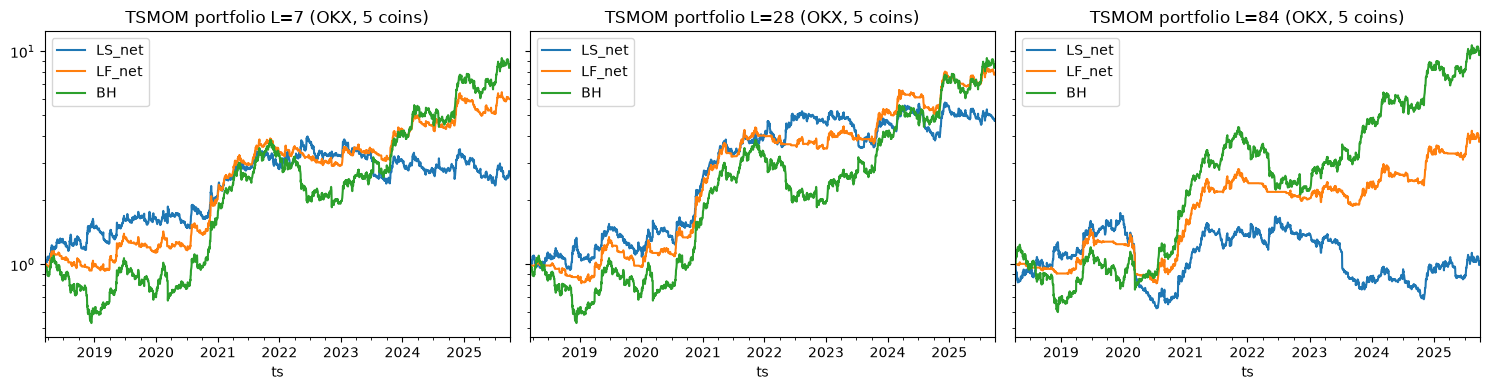

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, L in zip(axes, LS):
    for ver in ['LS_net', 'LF_net', 'BH']:
        (1 + port_store[L][ver]).cumprod().plot(ax=ax, logy=True, label=ver)
    ax.set_title(f'TSMOM portfolio L={L} (OKX, 5 coins)'); ax.legend()
plt.tight_layout()

**Reading ($L=28$).** Long/flat net: Sharpe **1.27** vs 0.97 for vol-scaled B&H over the full period (HAC p 0.002,
BH p<sub>adj</sub> 0.026). But LF minus B&H has mean $\approx 0$ (p 0.70): being flat in down-trends cuts volatility
and drawdowns without adding return - the edge is **risk reduction**. Long/short is weaker (net Sharpe 0.83) because
the short leg loses in crypto's up-drift. Since 2022 LF net Sharpe is 0.92 vs B&H 0.90 - no meaningful edge in the
recent half. *Nuance:* the "BH" rows are buy & hold, not a test - their significance only says crypto went up. All
coins rows (Coinbase, other $L$) are in the full `PORT` table above.

## Collected p-values
All 231 raw p-values with Benjamini-Hochberg adjustment, saved to `results/pvals/H0002.csv` for a
cross-hypothesis correction.

In [13]:
cols = ['test', 'source', 'coin', 'variant', 'period', 'horizon', 'n_event', 'diff', 'hac_t', 'hac_p', 'boot_lo', 'boot_hi']
PVALS = pd.concat([EV, PORT], ignore_index=True)[cols].rename(columns={'diff': 'effect'})
PVALS['diff'] = PVALS['effect']
PVALS['ci_lo'], PVALS['ci_hi'] = PVALS.boot_lo, PVALS.boot_hi
PVALS['hac_p_adj'] = adjust_pvalues(PVALS.hac_p.values)
out = ROOT / 'results' / 'pvals'
out.mkdir(parents=True, exist_ok=True)
PVALS.to_csv(out / 'H0002.csv', index=False)
print(len(PVALS), 'rows; min p_adj', PVALS.hac_p_adj.min().round(4), 'median p_adj', PVALS.hac_p_adj.median().round(4))

231 rows; min p_adj 0.0008 median p_adj 0.4178


## Connections

| Linked | Shared term | Relationship |
|---|---|---|
| H0012 Donchian / N-day high | $P_t$ vs past window | Breakout = another trend definition; corr 0.87 with this LF sleeve - same factor |
| S0004 trend ensemble | | Strategy built on this and H0012 |

**Derived ideas:** (1) continuous size $\propto z_L$ instead of the sign; (2) better $\sigma_t$ forecasts
(intraday realised vol, HAR) for $w_t$; (3) implied volatility (Deribit DVOL) in place of
$\sigma_t$ and the variance risk premium as a trend-regime filter; (4) BTC's $z_L$ as a lead
signal for alts.

## Verdict vs pass criteria

In [14]:
from qr.report import verdict_table
e = PVALS.query("test=='event' and source=='okx' and period=='full' and horizon==7 and variant=='L=28'")
pf = PVALS.query("test=='portfolio' and source=='okx' and variant=='L=28:LF_net'").set_index('period')
n_bh = int(((e.effect > 0) & (e.hac_p_adj < 0.05)).sum())
n_ci = int((e.ci_lo > 0).sum())
sub = EV.query("horizon==7 and variant=='L=28' and source=='okx' and period in ['2018-2021','2022+']").pivot_table(index='coin', columns='period', values='diff')
n_both = int((sub > 0).all(axis=1).sum())
sh = PORT.query("source=='okx' and period=='full'").set_index('variant').sharpe
display(verdict_table([
    ("L=28, h=7: diff > 0 and BH p_adj < 0.05 on >= 3/5 coins", f"{n_bh}/5 (SOL only)", n_bh >= 3),
    ("L=28, h=7: block-bootstrap CI excludes 0 on >= 3/5 coins", f"{n_ci}/5", n_ci >= 3),
    ("Same sign in both sub-periods (2018-21, 2022+) on >= 3/5 coins", f"{n_both}/5", n_both >= 3),
    ("Effect > 0.2% round-trip cost", f"{e.effect.min():+.2%} .. {e.effect.max():+.2%} per 7d", bool(e.effect.min() > 0.002)),
    ("Portfolio LF net: BH p_adj < 0.05", f"{pf.loc['full','hac_p_adj']:.3f}", bool(pf.loc['full','hac_p_adj'] < 0.05)),
    ("Portfolio LF net Sharpe > B&H Sharpe (full)", f"{sh['L=28:LF_net']:.2f} vs {sh['L=28:BH']:.2f}", bool(sh['L=28:LF_net'] > sh['L=28:BH'])),
    ("Portfolio LF net significant in 2022+", f"p {pf.loc['2022+','hac_p']:.2f}", "borderline" if pf.loc['2022+','hac_p'] < 0.2 else False),
]))

criterion,value,result
"L=28, h=7: diff > 0 and BH p_adj < 0.05 on >= 3/5 coins",0/5 (SOL only),fail
"L=28, h=7: block-bootstrap CI excludes 0 on >= 3/5 coins",2/5,fail
"Same sign in both sub-periods (2018-21, 2022+) on >= 3/5 coins",4/5,pass
Effect > 0.2% round-trip cost,+1.22% .. +5.35% per 7d,pass
Portfolio LF net: BH p_adj < 0.05,0.028,pass
Portfolio LF net Sharpe > B&H Sharpe (full),1.28 vs 0.97,pass
Portfolio LF net significant in 2022+,p 0.11,borderline


## Conclusion

**Verdict: WEAK-confirmed.** The per-coin criterion fails (1/5 coins after BH), but the effect has the right sign on
5/5 coins, both sub-periods and an independent 2015-2017 Coinbase sample, clears costs, and the long/flat
portfolio passes after BH. It is a **risk-reduction** effect: going flat in down-trends keeps buy & hold's return with
less volatility and much smaller drawdowns. It is weaker after 2022.

**Caveats.**
- Five correlated survivor coins (today's large caps) - effectively one or two independent bets.
- SOL drives the strongest numbers (2020-21 run); LTC/SOL OKX history starts 2020.
- The minimum detectable effect is about 1.5-4% per 7 days per coin, so per-coin tests are underpowered.
- Daily only; the papers are monthly. Re-run of 2026-10-30 uses pre-holdout data (to 2025-09-30) and a block
  bootstrap; the headline numbers moved slightly vs the first run (Sharpe 1.14 -> 1.27 net LF) but the verdict did not.

**Next steps.** Continuous sizing by $z_L$; better volatility forecasts for $w_t$; implied-vol / VRP filter (Deribit
DVOL); multi-timeframe re-run.